BANKDECISION is a structured financial dataset designed for exploratory data analysis, credit risk assessment, and machine learning applications.

The dataset contains 10,000 loan application records, including demographic information, educational background, income, employment experience, housing status, loan characteristics, and credit history.

It provides an opportunity to investigate the factors associated with financial decision-making and develop predictive models for binary credit decision classification.

The below model covers from data preparation, data cleansing, exploratory data analysis, building pipeline and logistic regression topics

Importing Required Libraries

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

In [2]:
credit_data = pd.read_excel('/Users/maheshg/Dropbox/Sample Datasets Kaggle/BANKDECISION.xlsx')

In [3]:
credit_data.head()

,Age,Genre,Educational level,Incomes,Years of work experience,State ownership,Amount,Purpose,Interest Rate,Percentage of income from loans,Loan duration,Credit history,Unpaid previous loans,Final Decision
0,24,male,Bachelor,109039,0,MORTGAGE,1700,VENTURE,10.75,0.02,3,665,No,NaN
1,37,female,Bachelor,361023,16,MORTGAGE,25000,EDUCATION,11.49,0.07,14,650,No,NaN
2,23,male,Bachelor,49066,1,RENT,12000,DEBTCONSOLIDATION,12.18,0.24,4,595,Yes,NaN
3,28,male,Master,51512,8,RENT,5000,MEDICAL,5.42,0.10,5,590,No,NaN
4,24,male,Bachelor,159550,0,MORTGAGE,1500,DEBTCONSOLIDATION,17.27,0.01,2,600,No,NaN


In [4]:
credit_data.columns

Index(['Age', 'Genre', 'Educational level', 'Incomes',
       'Years of work experience', 'State ownership', 'Amount', 'Purpose',
       'Interest Rate', 'Percentage of income from loans', 'Loan duration',
       'Credit history', 'Unpaid previous loans', 'Final Decision'],
      dtype='object')

In [5]:
print(credit_data.dtypes)

Age                                  int64
Genre                               object
Educational level                   object
Incomes                              int64
Years of work experience             int64
State ownership                     object
Amount                               int64
Purpose                             object
Interest Rate                      float64
Percentage of income from loans    float64
Loan duration                        int64
Credit history                       int64
Unpaid previous loans               object
Final Decision                     float64
dtype: object


In [6]:
credit_data.ndim

2

In [7]:
credit_data.size

140000

In [8]:
print(credit_data.describe())

                Age       Incomes  Years of work experience        Amount  \
count  10000.000000  1.000000e+04              10000.000000  10000.000000   
mean      27.719900  7.268343e+04                  5.378600  10071.440100   
std        6.123691  5.663583e+04                  6.125228   6667.989712   
min       20.000000  8.000000e+03                  0.000000   1000.000000   
25%       24.000000  4.187375e+04                  1.000000   5000.000000   
50%       26.000000  6.109400e+04                  4.000000   8500.000000   
75%       30.000000  8.759725e+04                  8.000000  14000.000000   
max      144.000000  2.448661e+06                121.000000  35000.000000   

       Interest Rate  Percentage of income from loans  Loan duration  \
count   10000.000000                     10000.000000   10000.000000   
mean       11.661898                         0.162106       5.876000   
std         3.140490                         0.098699       3.928762   
min         5.4200

In [9]:
print(credit_data.isna().sum())

Age                                   0
Genre                                 0
Educational level                     0
Incomes                               0
Years of work experience              0
State ownership                       0
Amount                                0
Purpose                               0
Interest Rate                         0
Percentage of income from loans       0
Loan duration                         0
Credit history                        0
Unpaid previous loans                 0
Final Decision                     1500
dtype: int64


In [10]:
credit_data["Final Decision"].value_counts()

Final Decision
1.0    4257
0.0    4243
Name: count, dtype: int64

Visualization 

<Axes: xlabel='Final Decision', ylabel='count'>

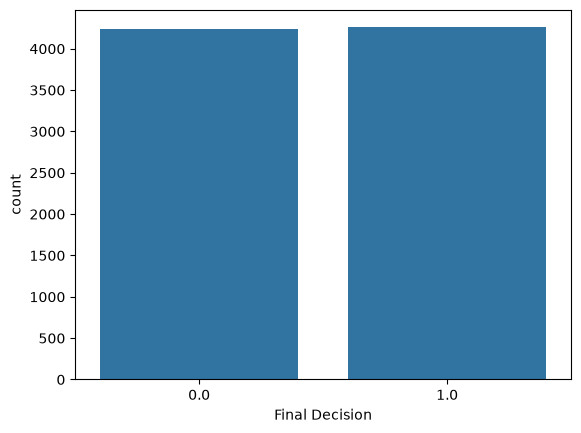

In [11]:
sns.countplot(x = "Final Decision", data = credit_data)

Now Removing Unlabelled Records

In [12]:
credit_data["Final Decision"].isnull().sum()

np.int64(1500)

In [13]:
credit_data_model = credit_data.dropna(subset = ["Final Decision"])

In [14]:
credit_data_model.shape

(8500, 14)

Performing Exploratory Data Analysis 

Age Distribution

<Axes: xlabel='Age', ylabel='Count'>

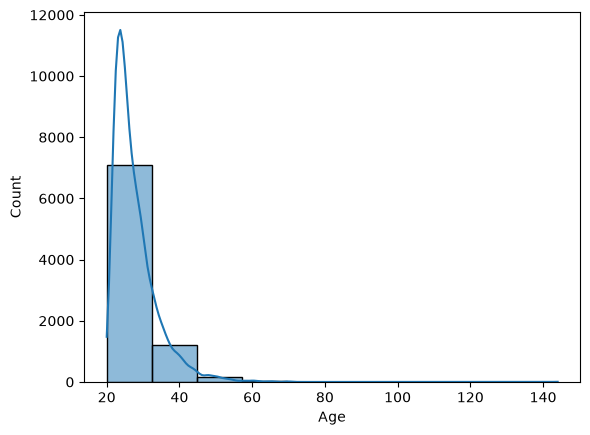

In [15]:
sns.histplot(credit_data_model["Age"],bins = 10, kde = True)

Income Distribution

<Axes: xlabel='Final Decision', ylabel='Age'>

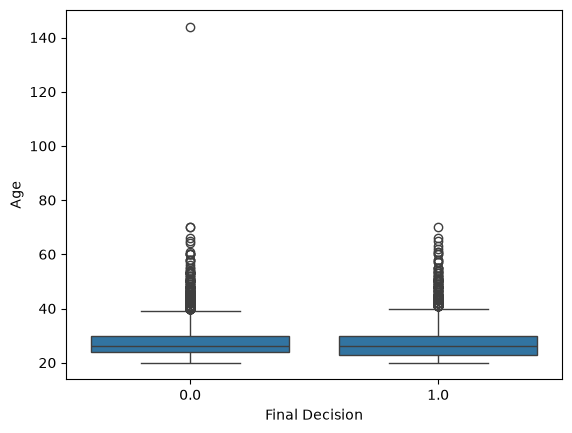

In [16]:
sns.boxplot(x = "Final Decision", y = "Age", data = credit_data_model)

Credit Score Distribution

<Axes: xlabel='Credit history', ylabel='Count'>

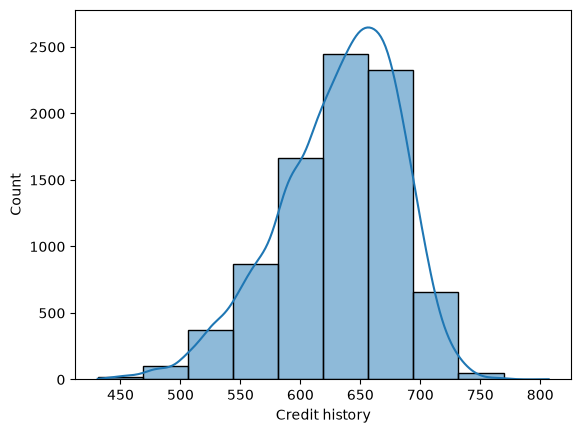

In [17]:
sns.histplot(credit_data_model["Credit history"],bins = 10, kde = True)

Relationship with the decision making

<Axes: xlabel='Final Decision', ylabel='Age'>

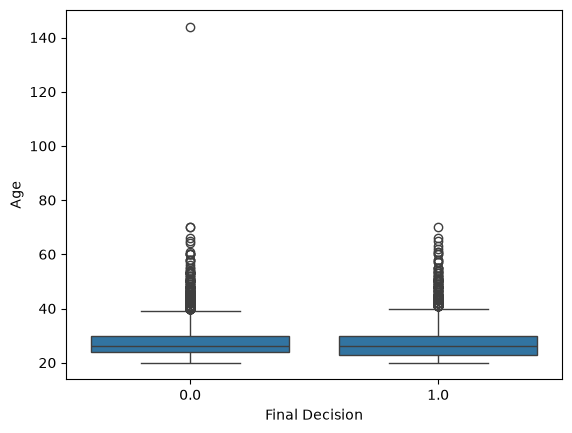

In [18]:
sns.boxplot(x = "Final Decision", y = "Age", data = credit_data_model)

Feature Engineering

In [19]:
categorical_cols = [
    "Genre",
    "Educational level",
    "State ownership",
    "Purpose",
    "Unpaid previous loans"
]

One Hot Encoding:

In [20]:
credit_data_model = pd.get_dummies(
    credit_data_model,
    columns = categorical_cols,
    drop_first = True
)

Preparing the features and Target

In [21]:
X = credit_data_model.drop(columns = ["Final Decision"])
y = credit_data_model["Final Decision"]

Creating the train and split of test data

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y)

Logistic Regression Model

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [25]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter = 1000, random_state = 42))

In [26]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['Age','Incomes','Years of work experience',...,'Purpose_PERSONAL', 'Purpose_VENTURE','Unpaid previous loans_Yes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [27]:
predictions = model.predict(X_test)

Evaluation of Model : 

In [28]:
from sklearn.metrics import classification_report, confusion_matrix,roc_auc_score,roc_curve

In [29]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

         0.0       0.92      0.83      0.87       849
         1.0       0.85      0.93      0.88       851

    accuracy                           0.88      1700
   macro avg       0.88      0.88      0.88      1700
weighted avg       0.88      0.88      0.88      1700



In [30]:
cm = confusion_matrix(y_test, predictions)

In [31]:
cm

array([[705, 144],
       [ 63, 788]])

<Axes: >

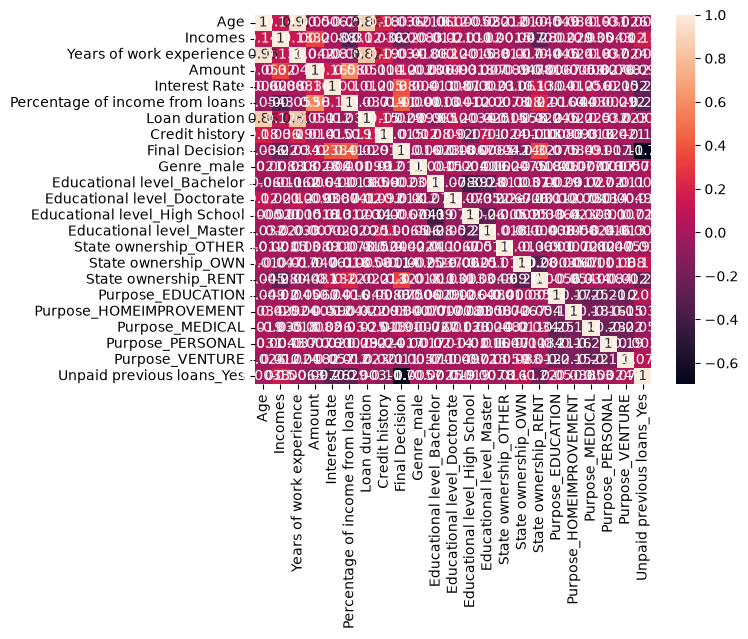

In [32]:
sns.heatmap(credit_data_model.corr(), annot = True)